<a href="https://colab.research.google.com/github/aniruddhajoshi100/DefectGAN/blob/data/dcgan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"hariharankl","key":"fea78bb45022627da45798552fcc5667"}'}

In [ ]:
! mkdir ~/.kaggle

In [ ]:
!cp kaggle.json ~/.kaggle/


In [ ]:
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download akhatova/pcb-defects

Dataset URL: https://www.kaggle.com/datasets/akhatova/pcb-defects
License(s): unknown
100% 1.87G/1.88G [00:17<00:00, 185MB/s]
100% 1.88G/1.88G [00:17<00:00, 112MB/s]


In [ ]:
!unzip pcb-defects.zip

Archive:  pcb-defects.zip
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_01.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_02.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_03.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_04.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_05.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_06.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_07.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_08.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_09.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_10.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_11.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_12.xml  
  inflating: PCB_DATASET/Annotations/Missing_hole/01_missing_hole_13.xml  

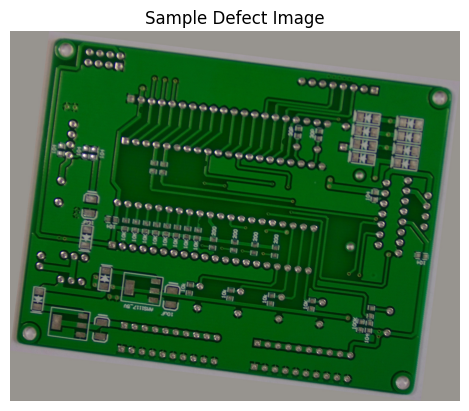

In [ ]:
import matplotlib.pyplot as plt
import cv2
import os

# Example: Set path to one image
image_path = "PCB_DATASET/rotation/Mouse_bite_rotation/09_mouse_bite_04.jpg"  # replace with your actual path

# Load the image using OpenCV
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB for matplotlib

# Display the image
plt.imshow(image)
plt.title("Sample Defect Image")
plt.axis('off')
plt.show()


In [ ]:
from PIL import Image
import os

input_root = "/content/PCB_DATASET/images"
output_root = "/content/preprocessed"

os.makedirs(output_root, exist_ok=True)

for defect_type in os.listdir(input_root):
    input_path = os.path.join(input_root, defect_type)
    output_path = os.path.join(output_root, defect_type)
    os.makedirs(output_path, exist_ok=True)

    for fname in os.listdir(input_path):
        if fname.lower().endswith(('.jpg', '.png')):
            img = Image.open(os.path.join(input_path, fname)).convert("RGB")
            img = img.resize((128, 128), Image.LANCZOS)
            img.save(os.path.join(output_path, fname))


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "<ipython-input-12-3219694695>", line 16, in <cell line: 0>
    img = Image.open(os.path.join(input_path, fname)).convert("RGB")
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/PIL/Image.py", line 982, in convert
    self.load()
  File "/usr/local/lib/python3.11/dist-packages/PIL/ImageFile.py", line 389, in load
    n, err_code = decoder.decode(b)
                  ^^^^^^^^^^^^^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/IPython/core/interactiveshell.py", line 2099, in showtraceback
    stb = value._render_traceback_()
          ^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: 'KeyboardInterrupt' o

TypeError: object of type 'NoneType' has no len()

In [ ]:
from PIL import Image
base_path = "/content/preprocessed"

# Check one image from each folder
for folder in os.listdir(base_path):
    img_path = os.path.join(base_path, folder, os.listdir(os.path.join(base_path, folder))[0])
    img = Image.open(img_path)
    print(f"{folder} - {img.size}")


In [ ]:
import matplotlib.pyplot as plt
import random

folder = random.choice(os.listdir(base_path))
image_file = random.choice(os.listdir(os.path.join(base_path, folder)))
image_path = os.path.join(base_path, folder, image_file)

img = Image.open(image_path)
plt.imshow(img)
plt.title(f"{folder} Sample")
plt.axis('off')
plt.show()


In [ ]:
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils
import torchvision.utils as vutils
from torchvision.utils import make_grid
from PIL import Image
import matplotlib.pyplot as plt
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [ ]:
class PCBDefectDataset(Dataset):
    def __init__(self, root_dir):
        self.image_paths = []
        for defect_type in os.listdir(root_dir):
            defect_path = os.path.join(root_dir, defect_type)
            for filename in os.listdir(defect_path):
                if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                    self.image_paths.append(os.path.join(defect_path, filename))

        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5])
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert('RGB')
        return self.transform(image)

data_path = "/content/preprocessed"
dataset = PCBDefectDataset(data_path)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True, num_workers=2)

print(f"Total images loaded: {len(dataset)}")


Total images loaded: 461


In [ ]:
class Generator(nn.Module):
    def __init__(self, z_dim, img_channels, features_g):
        super().__init__()
        self.gen = nn.Sequential(
            self._block(z_dim, features_g * 16, 4, 1, 0),  # 1 → 4
            self._block(features_g * 16, features_g * 8, 4, 2, 1),  # 4 → 8
            self._block(features_g * 8, features_g * 4, 4, 2, 1),   # 8 → 16
            self._block(features_g * 4, features_g * 2, 4, 2, 1),   # 16 → 32
            self._block(features_g * 2, features_g, 4, 2, 1),       # 32 → 64
            nn.ConvTranspose2d(features_g, img_channels, 4, 2, 1),  # 64 → 128
            nn.Tanh()
        )

    def _block(self, in_c, out_c, k, s, p):
        return nn.Sequential(
            nn.ConvTranspose2d(in_c, out_c, k, s, p, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(True)
        )

    def forward(self, x):
        return self.gen(x)


In [ ]:
class Discriminator(nn.Module):
    def __init__(self, img_channels, features_d):
        super().__init__()
        self.disc = nn.Sequential(
            nn.Conv2d(img_channels, features_d, 4, 2, 1),  # 128 → 64
            nn.LeakyReLU(0.2),
            self._block(features_d, features_d * 2, 4, 2, 1),  # 64 → 32
            self._block(features_d * 2, features_d * 4, 4, 2, 1),  # 32 → 16
            self._block(features_d * 4, features_d * 8, 4, 2, 1),  # 16 → 8
            self._block(features_d * 8, features_d * 16, 4, 2, 1),  # 8 → 4
            nn.Conv2d(features_d * 16, 1, 4, 1, 0),  # 4 → 1
            nn.Sigmoid()
        )

    def _block(self, in_c, out_c, k, s, p):
        return nn.Sequential(
            nn.Conv2d(in_c, out_c, k, s, p, bias=False),
            nn.BatchNorm2d(out_c),
            nn.LeakyReLU(0.2, inplace=True)
        )

    def forward(self, x):
        return self.disc(x)


In [ ]:
z_dim = 100
img_channels = 3
features_g = 64
features_d = 64

netG = Generator(z_dim, img_channels, features_g).to(device)
netD = Discriminator(img_channels, features_d).to(device)

netG.load_state_dict(torch.load("netG_epoch5.pth"))
netD.load_state_dict(torch.load("netD_epoch5.pth"))

criterion = nn.BCELoss()
optimizerG = torch.optim.Adam(netG.parameters(), lr=2e-4, betas=(0.5, 0.999))
optimizerD = torch.optim.Adam(netD.parameters(), lr=2e-4, betas=(0.5, 0.999))

fixed_noise = torch.randn(64, z_dim, 1, 1, device=device)


In [ ]:
start_epoch=11
num_epochs = 13
os.makedirs("generated_images", exist_ok=True)

for epoch in range(start_epoch,num_epochs+1):
    for batch_idx, real in enumerate(dataloader):
        real = real.to(device)
        b_size = real.size(0)
        noise = torch.randn(b_size, z_dim, 1, 1, device=device)
        fake = netG(noise)

        netD.zero_grad()
        label_real = torch.full((b_size,), 1.0, device=device)
        label_fake = torch.full((b_size,), 0.0, device=device)

        output_real = netD(real).view(-1)
        lossD_real = criterion(output_real, label_real)

        output_fake = netD(fake.detach()).view(-1)
        lossD_fake = criterion(output_fake, label_fake)

        lossD = lossD_real + lossD_fake
        lossD.backward()
        optimizerD.step()

        netG.zero_grad()
        output = netD(fake).view(-1)
        lossG = criterion(output, label_real)
        lossG.backward()
        optimizerG.step()
        D_x = output_real.mean().item()
        D_G_z = output_fake.mean().item()

        if batch_idx % 50 == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}] Batch {batch_idx}/{len(dataloader)} "
                  f"Loss D: {lossD.item():.4f}, Loss G: {lossG.item():.4f} "
                  f"D(x): {D_x:.4f}, D(G(z)): {D_G_z:.4f}")

    if (epoch + 1) % 5 == 0:
      with torch.no_grad():
          fake = netG(fixed_noise).detach().cpu()
      img_grid = vutils.make_grid(fake, normalize=True)
      vutils.save_image(img_grid, f"generated_images/fake_samples_epoch_{epoch+1}.png")
      print(f"✅ Saved image for epoch {epoch+1}")

    torch.save(netG.state_dict(), f"netG_epoch{epoch+1}.pth")
    torch.save(netD.state_dict(), f"netD_epoch{epoch+1}.pth")
    print(f"💾 Saved model weights for epoch {epoch+1}")


Epoch [12/13] Batch 0/8 Loss D: 1.3539, Loss G: 8.6150 D(x): 0.6342, D(G(z)): 0.5822


KeyboardInterrupt: 

In [ ]:
with torch.no_grad():
    fake = netG(fixed_noise).detach().cpu()
img_grid = make_grid(fake, normalize=True)
plt.figure(figsize=(8, 8))
plt.axis("off")
plt.title("Generated Images")
plt.imshow(img_grid.permute(1, 2, 0))
plt.show()


In [ ]:
torch.save(netG.state_dict(), "netG_final.pth")
torch.save(netD.state_dict(), "netD_final.pth")

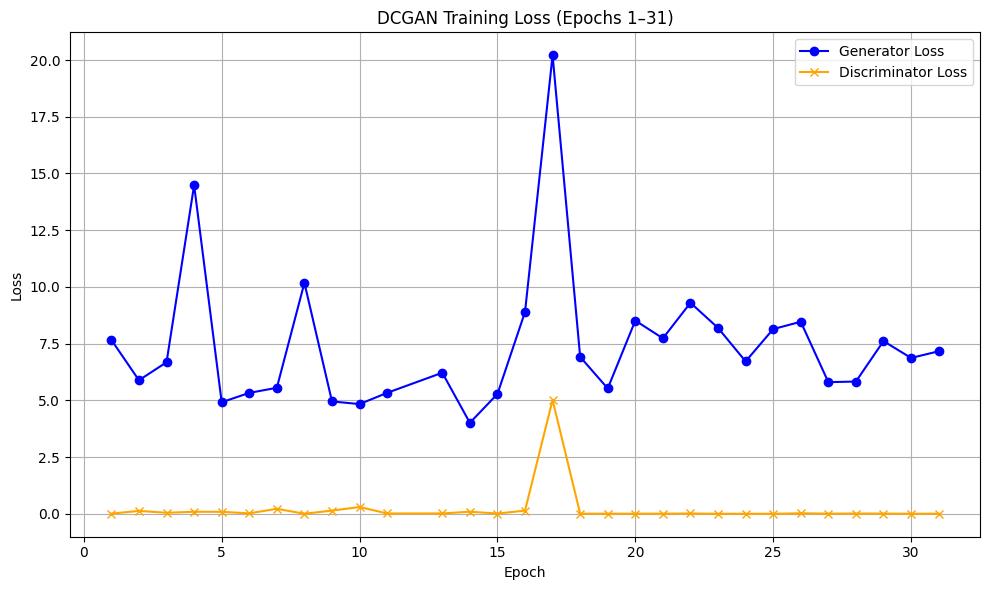

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Epochs 1–31
epochs = list(range(1, 32))


lossD = [
    0.0108, 0.1307, 0.0480, 0.0919, 0.0895, 0.0229, 0.2228, 0.0056, 0.1435, 0.3013, 0.0174,
    None,
    0.0190, 0.0946, 0.0132, 0.1439, 5.0193, 0.0074, 0.0073, 0.0075, 0.0085,
    0.0162, 0.0048, 0.0042, 0.0029, 0.0256, 0.0091, 0.0150, 0.0115, 0.0051, 0.0081
]


lossG = [
    7.6642, 5.8884, 6.6808, 14.4856, 4.9191, 5.3308, 5.5562, 10.1798, 4.9541, 4.8376, 5.3333,
    None,
    6.2185, 4.0121, 5.2825, 8.8955, 20.2093, 6.9184, 5.5257, 8.5177, 7.7353,
    9.3016, 8.1932, 6.7199, 8.1423, 8.4661, 5.8043, 5.8308, 7.6132, 6.8706, 7.1639
]

# Convert to NumPy
epochs_np = np.array(epochs)
lossD_np = np.array(lossD, dtype=np.float32)
lossG_np = np.array(lossG, dtype=np.float32)

# Mask to remove None (now NaN) for plotting
mask = ~np.isnan(lossD_np) & ~np.isnan(lossG_np)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(epochs_np[mask], lossG_np[mask], label="Generator Loss", marker='o', color='blue')
plt.plot(epochs_np[mask], lossD_np[mask], label="Discriminator Loss", marker='x', color='orange')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss (Epochs 1–31)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("dcgan_loss_full.png")
plt.show()
